In [3]:
import pandas as pd

In [4]:
df = pd.read_csv(r"C:\Users\arpit\Downloads\Retail and wherehouse Sale (1) python capstone.csv")

In [5]:
df.head()

,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
0,2020,1,REPUBLIC NATIONAL DISTRIBUTING CO,100009,BOOTLEG RED - 750ML,WINE,0.00,0.0,2.0
1,2020,1,PWSWN INC,100024,MOMENT DE PLAISIR - 750ML,WINE,0.00,1.0,4.0
2,2020,1,RELIABLE CHURCHILL LLLP,1001,S SMITH ORGANIC PEAR CIDER - 18.7OZ,BEER,0.00,0.0,1.0
3,2020,1,LANTERNA DISTRIBUTORS INC,100145,SCHLINK HAUS KABINETT - 750ML,WINE,0.00,0.0,1.0
4,2020,1,DIONYSOS IMPORTS INC,100293,SANTORINI GAVALA WHITE - 750ML,WINE,0.82,0.0,0.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   YEAR              30000 non-null  int64  
 1   MONTH             30000 non-null  int64  
 2   SUPPLIER          29967 non-null  object 
 3   ITEM CODE         30000 non-null  object 
 4   ITEM DESCRIPTION  30000 non-null  object 
 5   ITEM TYPE         30000 non-null  object 
 6   RETAIL SALES      29999 non-null  float64
 7   RETAIL TRANSFERS  30000 non-null  float64
 8   WAREHOUSE SALES   30000 non-null  float64
dtypes: float64(3), int64(2), object(4)
memory usage: 2.1+ MB


In [7]:
df.shape

(30000, 9)

In [8]:
df.isnull().sum()

YEAR                 0
MONTH                0
SUPPLIER            33
ITEM CODE            0
ITEM DESCRIPTION     0
ITEM TYPE            0
RETAIL SALES         1
RETAIL TRANSFERS     0
WAREHOUSE SALES      0
dtype: int64

In [9]:
df[df["SUPPLIER"].isnull()]

,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
106,2020,1,NaN,107,JIGGER MEASURE SHOT GLASS,STR_SUPPLIES,14.69,18.0,0.0
188,2020,1,NaN,113,BARTENDERS BLACK BOOK,STR_SUPPLIES,0.40,0.0,0.0
231,2020,1,NaN,115,PLASTIC SHOT GLASS PACK,STR_SUPPLIES,5.71,6.0,0.0
252,2020,1,NaN,117,WHISKEY TASTING JOURNAL,STR_SUPPLIES,0.08,0.0,0.0
261,2020,1,NaN,118,PLASTIC WINE GLASS PACK,STR_SUPPLIES,7.40,10.0,0.0
281,2020,1,NaN,119,BRUMATE WINE TUMBLER,STR_SUPPLIES,9.00,32.0,0.0
295,2020,1,NaN,120,WHISKEY BARREL,STR_SUPPLIES,4.00,0.0,0.0
344,2020,1,NaN,123,HOLIDAY TOTE FOIL BAG,STR_SUPPLIES,3.89,0.0,0.0
405,2020,1,NaN,1279,EMPTY WINE KEG - KEGS,DUNNAGE,0.00,0.0,-12.0
981,2020,1,NaN,2,ICE,NON-ALCOHOL,542.00,0.0,0.0


In [10]:
df[df["RETAIL SALES"].isnull()]

,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
18390,2020,7,NaN,4,RMS ITEM,NON-ALCOHOL,NaN,0.0,0.0


In [11]:
df["SUPPLIER"] = df["SUPPLIER"].fillna("Unknown")

In [12]:
df["RETAIL SALES"] = df["RETAIL SALES"].fillna(0)

In [13]:
df.isnull().sum()

YEAR                0
MONTH               0
SUPPLIER            0
ITEM CODE           0
ITEM DESCRIPTION    0
ITEM TYPE           0
RETAIL SALES        0
RETAIL TRANSFERS    0
WAREHOUSE SALES     0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df[df.duplicated()]

,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES


In [16]:
(df[["RETAIL SALES", "RETAIL TRANSFERS", "WAREHOUSE SALES"]] < 0).sum()

RETAIL SALES         6
RETAIL TRANSFERS    16
WAREHOUSE SALES     76
dtype: int64

# KPI'S

In [17]:
df[["RETAIL SALES", "RETAIL TRANSFERS", "WAREHOUSE SALES"]].sum()

RETAIL SALES        208186.94
RETAIL TRANSFERS    197821.74
WAREHOUSE SALES     822930.93
dtype: float64

# EDA

In [19]:
monthly_sales = df.groupby("MONTH")[["RETAIL SALES", "RETAIL TRANSFERS","WAREHOUSE SALES"]].sum()

In [20]:
monthly_sales

,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
MONTH,,,
1,74318.77,75997.35,284114.72
3,34523.90,34505.08,113305.22
7,94538.96,82706.57,418094.42
9,4805.31,4612.74,7416.57


In [21]:
item_type_sales = df.groupby("ITEM TYPE")[["RETAIL SALES", "RETAIL TRANSFERS","WAREHOUSE SALES"]].sum().sort_values("RETAIL SALES", ascending=False)


In [22]:
item_type_sales

,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
ITEM TYPE,,,
LIQUOR,81742.85,79599.70,8796.90
WINE,59688.84,58629.13,119459.93
BEER,59538.76,55729.83,697279.68
NON-ALCOHOL,6824.62,2934.08,2438.42
STR_SUPPLIES,345.60,895.00,0.00
REF,46.27,34.00,-1329.00
DUNNAGE,0.00,0.00,-12115.00
KEGS,0.00,0.00,8400.00


In [23]:
supplier_sales = df.groupby("SUPPLIER")["RETAIL SALES"].sum().sort_values(ascending=False)

supplier_sales.head(10)

SUPPLIER
DIAGEO NORTH AMERICA INC        13840.54
E & J GALLO WINERY              12742.24
ANHEUSER BUSCH INC              10091.64
CONSTELLATION BRANDS             9931.78
JIM BEAM BRANDS CO               9845.79
CROWN IMPORTS                    9341.80
SAZERAC CO                       7739.14
MILLER BREWING COMPANY           7737.55
BACARDI USA INC                  6121.70
HEAVEN HILL DISTILLERIES INC     6075.45
Name: RETAIL SALES, dtype: float64

In [24]:
product_sales = df.groupby("ITEM DESCRIPTION")["RETAIL SALES"].sum().sort_values(ascending=False)

product_sales.head(10)

ITEM DESCRIPTION
ICE                                          3842.00
CORONA EXTRA LOOSE NR - 12OZ                 2845.00
TITO'S HANDMADE VODKA - 1.75L                2330.99
HEINEKEN LOOSE NR - 12OZ                     2096.00
STELLA ARTOIS LOOSE NR - 11.2OZ              1348.00
MILLER LITE  HIGH GRAPHIC LOOSE NR - 12OZ    1258.00
CORONA EXTRA 2/12 NR - 12OZ                  1105.00
MILLER LITE 30PK CAN - 12OZ                  1045.00
YUENGLING LAGER LOOSE NR - 12OZ               961.00
BUD LIGHT 30PK CAN                            958.00
Name: RETAIL SALES, dtype: float64

In [25]:
monthly_trend = df.groupby(["YEAR", "MONTH"])["RETAIL SALES"].sum().reset_index()

monthly_trend

,YEAR,MONTH,RETAIL SALES
0,2020,1,74318.77
1,2020,3,34523.90
2,2020,7,94538.96
3,2020,9,4805.31


In [26]:
sales_transfer = df[["RETAIL SALES", "RETAIL TRANSFERS"]].corr()

sales_transfer

,RETAIL SALES,RETAIL TRANSFERS
RETAIL SALES,1.000000,0.844598
RETAIL TRANSFERS,0.844598,1.000000


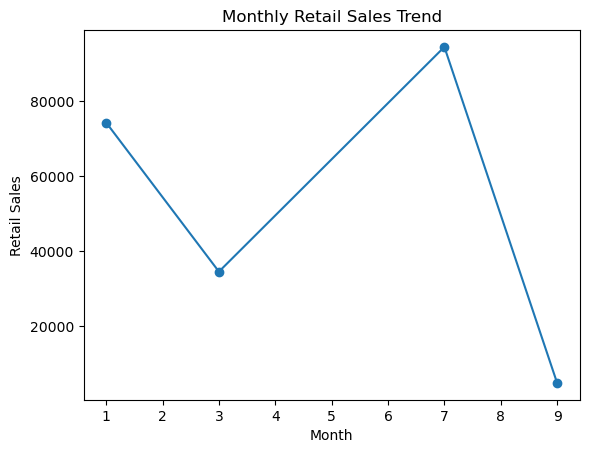

In [27]:
import matplotlib.pyplot as plt

monthly_sales = df.groupby("MONTH")["RETAIL SALES"].sum()

plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Retail Sales")
plt.title("Monthly Retail Sales Trend")
plt.show()

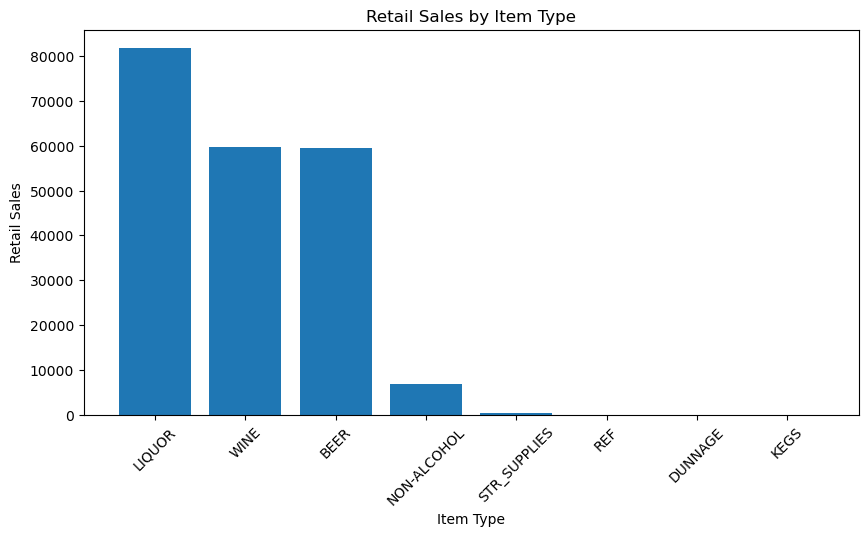

In [28]:
item_type_sales = df.groupby("ITEM TYPE")["RETAIL SALES"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(item_type_sales.index, item_type_sales.values)
plt.xlabel("Item Type")
plt.ylabel("Retail Sales")
plt.title("Retail Sales by Item Type")
plt.xticks(rotation=45)
plt.show()

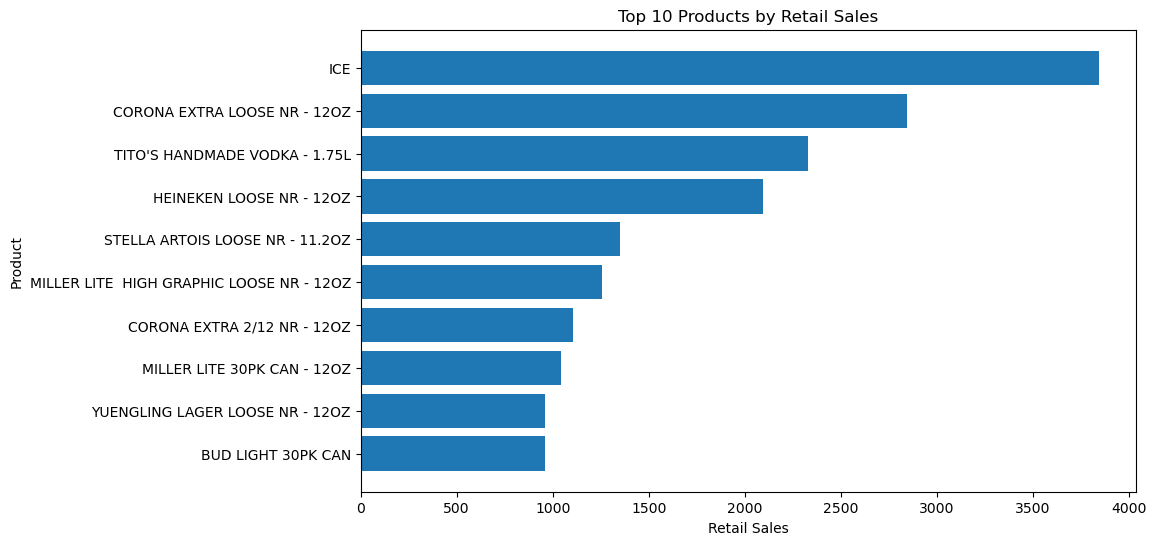

In [29]:
top_products = df.groupby("ITEM DESCRIPTION")["RETAIL SALES"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_products.index, top_products.values)
plt.xlabel("Retail Sales")
plt.ylabel("Product")
plt.title("Top 10 Products by Retail Sales")
plt.gca().invert_yaxis()
plt.show()

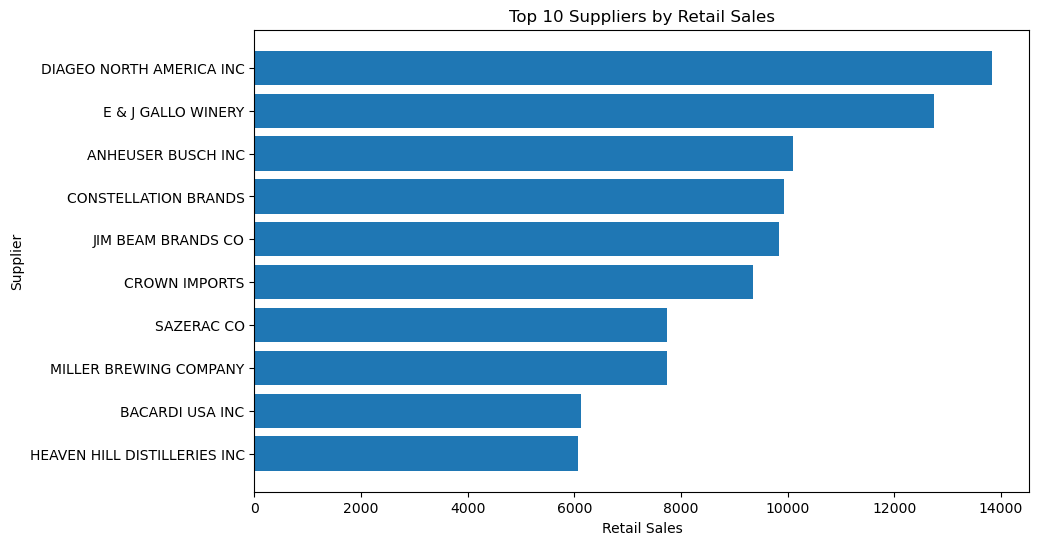

In [32]:
top_suppliers = df.groupby("SUPPLIER")["RETAIL SALES"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_suppliers.index, top_suppliers.values)
plt.xlabel("Retail Sales")
plt.ylabel("Supplier")
plt.title("Top 10 Suppliers by Retail Sales")
plt.gca().invert_yaxis()
plt.show()

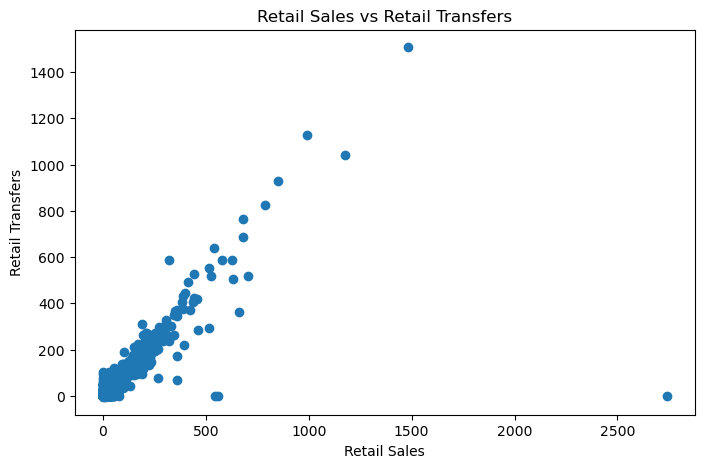

In [33]:
plt.figure(figsize=(8, 5))
plt.scatter(df["RETAIL SALES"], df["RETAIL TRANSFERS"])
plt.xlabel("Retail Sales")
plt.ylabel("Retail Transfers")
plt.title("Retail Sales vs Retail Transfers")
plt.show()

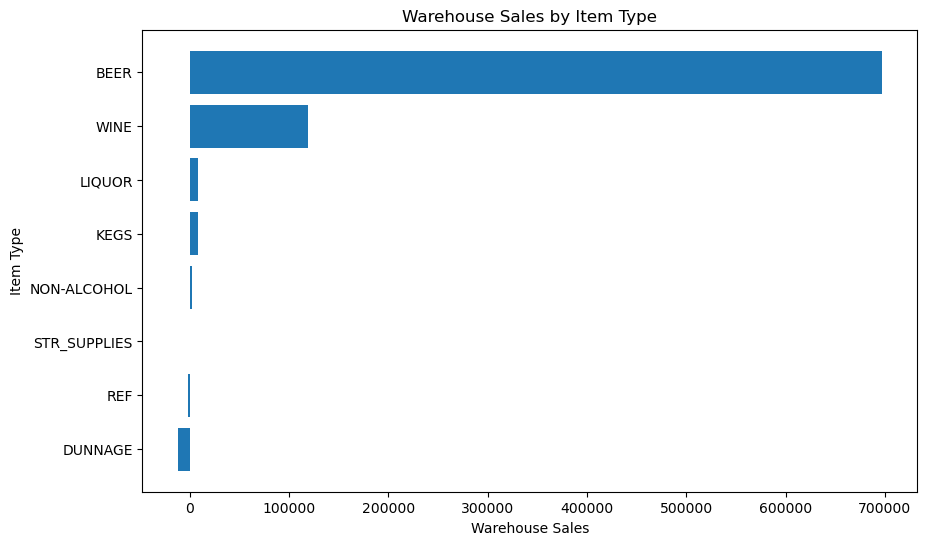

In [34]:
warehouse_by_type = df.groupby("ITEM TYPE")["WAREHOUSE SALES"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(warehouse_by_type.index, warehouse_by_type.values)
plt.xlabel("Warehouse Sales")
plt.ylabel("Item Type")
plt.title("Warehouse Sales by Item Type")
plt.gca().invert_yaxis()
plt.show()

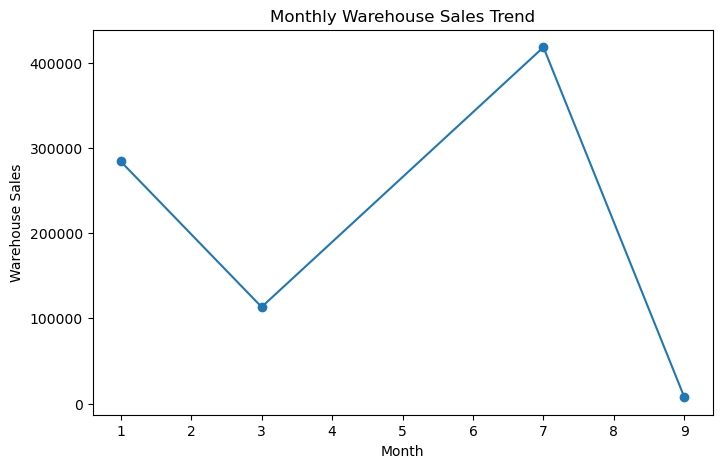

In [35]:
monthly_warehouse = df.groupby("MONTH")["WAREHOUSE SALES"].sum()

plt.figure(figsize=(8, 5))
plt.plot(monthly_warehouse.index, monthly_warehouse.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Warehouse Sales")
plt.title("Monthly Warehouse Sales Trend")
plt.show()

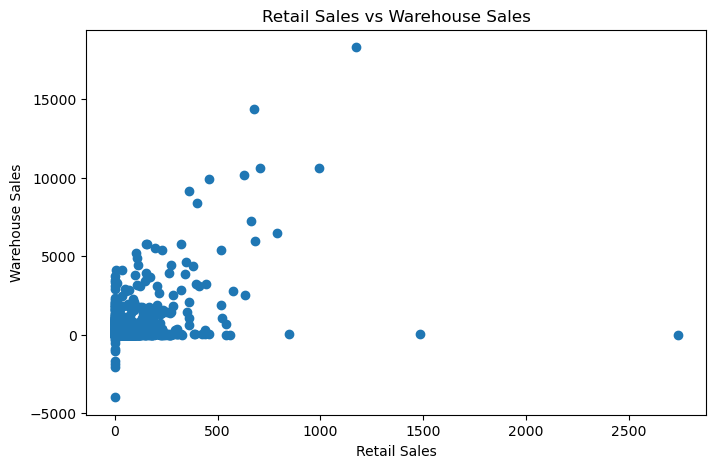

In [36]:
plt.figure(figsize=(8, 5))
plt.scatter(df["RETAIL SALES"], df["WAREHOUSE SALES"])
plt.xlabel("Retail Sales")
plt.ylabel("Warehouse Sales")
plt.title("Retail Sales vs Warehouse Sales")
plt.show()

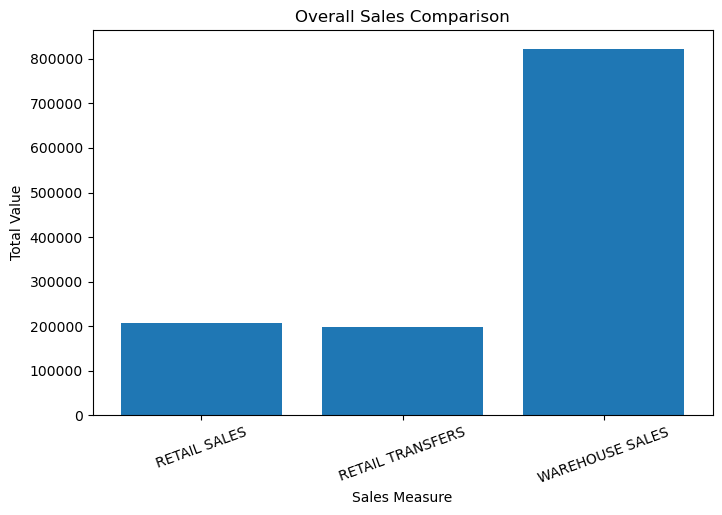

In [37]:
total_sales = df[[
    "RETAIL SALES",
    "RETAIL TRANSFERS",
    "WAREHOUSE SALES"
]].sum()

plt.figure(figsize=(8, 5))
plt.bar(total_sales.index, total_sales.values)
plt.xlabel("Sales Measure")
plt.ylabel("Total Value")
plt.title("Overall Sales Comparison")
plt.xticks(rotation=20)
plt.show()